In [1]:
# Import required analytical and visualization libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

In [6]:
# Define local pathing and the expected output files from the cluster
data_dir = "./data/panss_model/"

model_files = {
    "FC & FS Only": "predictions_FC_FS_only.npz",
    "GEC Only": "predictions_GEC_only.npz",
    "All Features": "predictions_ALL_features.npz"
}

def evaluate_model_performance(file_path):
    """
    Loads the LOOCV predictions from disk and computes core regression metrics.
    """
    data = np.load(file_path)
    y_true = data['y_true']
    y_pred = data['y_pred']
    
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return y_true, y_pred, mae, mape, r2

In [7]:
# Initialize storage for plotting data and tabular metrics
results_data = {}
metrics_list = []

for model_name, filename in model_files.items():
    file_path = os.path.join(data_dir, filename)
    
    if os.path.exists(file_path):
        y_true, y_pred, mae, mape, r2 = evaluate_model_performance(file_path)
        
        # Retain the raw arrays for the seaborn plots
        results_data[model_name] = {'y_true': y_true, 'y_pred': y_pred}
        
        # Record metrics for the summary table
        metrics_list.append({
            "Model": model_name,
            "MAE": mae,
            "MAPE": mape,
            "R² Score": r2
        })
    else:
        print(f"Warning: Could not locate {file_path}. Check the directory path.")

# Output the metrics as a clean pandas DataFrame using Jupyter's native display
metrics_df = pd.DataFrame(metrics_list)
display(metrics_df.round(4))

,Model,MAE,MAPE,R² Score
0,FC & FS Only,10.4541,0.2172,-0.2432
1,GEC Only,9.4467,0.1967,-0.0090
2,All Features,9.9872,0.2068,-0.1598


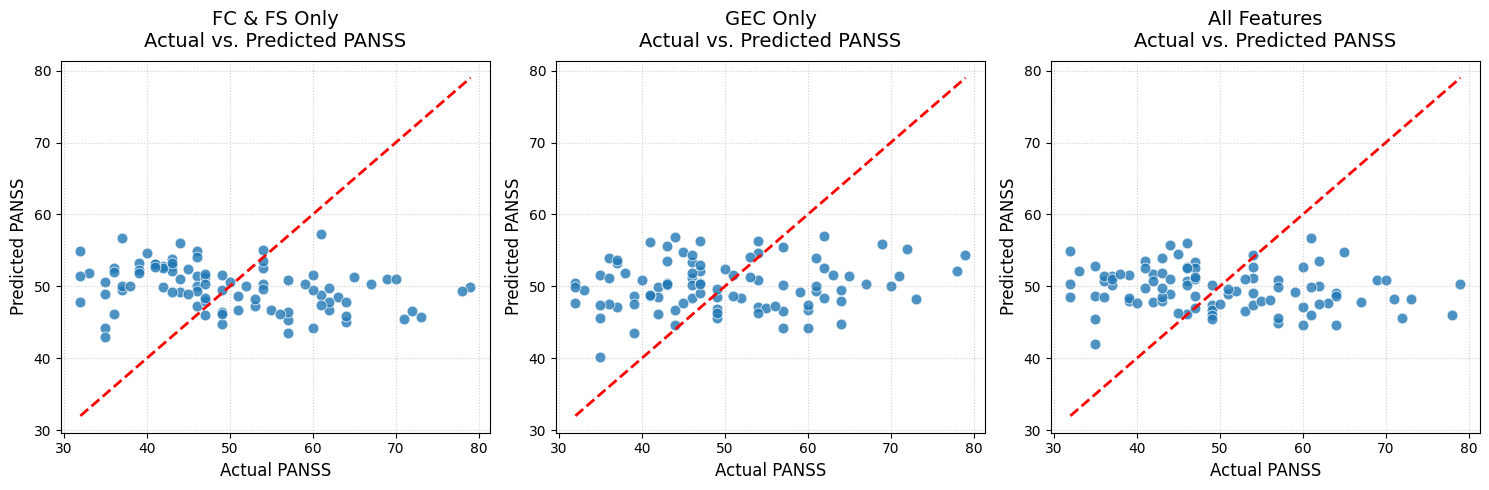

In [8]:
# Set up a side-by-side figure to compare all three models visually
fig, axes = plt.subplots(1, len(results_data), figsize=(len(results_data) * 5, 5))

# Handle the case where only one or two models successfully loaded
if len(results_data) == 1:
    axes = [axes]

for ax, (model_name, data) in zip(axes, results_data.items()):
    y_true = data['y_true']
    y_pred = data['y_pred']
    
    # Plot Actual vs Predicted scores
    sns.scatterplot(x=y_true, y=y_pred, ax=ax, color='#1f77b4', s=60, alpha=0.8)
    
    # Add the identity line representing perfect predictions
    min_val = min(min(y_true), min(y_pred))
    max_val = max(max(y_true), max(y_pred))
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
    
    # Format the plot aesthetics
    ax.set_title(f'{model_name}\nActual vs. Predicted PANSS', fontsize=14, pad=10)
    ax.set_xlabel('Actual PANSS', fontsize=12)
    ax.set_ylabel('Predicted PANSS', fontsize=12)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()